# Passive Dendritic Modelling: The Cable Equation

This exercise investigates passive spread and leakage of voltage along an idealised one-dimensional dendrite. The numerical method is a **finite-difference discretisation in space followed by ODE integration in time (Method of Lines)**. A Green-function construction for the infinite cable provides an independent analytical reference. The notebook imports the same tested functions used by `main.py` to avoid discrepancies between the two implementations.

## 1. Physical context and governing PDE

A passive dendrite acts as a distributed RC cable. Voltage propagates through longitudinal current flow and decreases because of membrane leakage. The voltage **deviation from rest** $V(x,t)$ satisfies

$$
\tau\frac{\partial V}{\partial t}=\lambda^2\frac{\partial^2 V}{\partial x^2}-V+I(x,t).
$$

The cable space constant $\lambda$ has units **µm** and membrane time constant $\tau$ has units **ms**. The effective diffusion coefficient is $D=\lambda^2/\tau$. The input $I(x,t)$ is measured in **voltage-equivalent mV**, not in physical current density; physical current would require an additional membrane resistance conversion.

We start at rest, $V(x,0)=0$, and clamp both **finite-cable endpoints** to rest: $V(0,t)=V(L,t)=0$ (Dirichlet boundary conditions). An effective square pulse is applied to the midpoint grid cell from 10 to 40 ms. Clamped ends differ from sealed-end boundaries and from an infinite cable.

## 2. Spatial finite differences and the sparse matrix

For $N$ spatial nodes including the endpoints, $x_i=i\Delta x$ and $\Delta x=L/(N-1)$. At each interior node the central difference formula is

$$
\frac{\partial^2 V}{\partial x^2}(x_i,t)\approx
\frac{V_{i-1}-2V_i+V_{i+1}}{\Delta x^2}.
$$

Hence the PDE becomes a system of coupled linear ODEs,

$$
\dot{\mathbf V}=\underbrace{\left(D\mathbf L_h-\frac1\tau\mathbf I\right)}_{\mathbf A}\mathbf V+\frac{\mathbf I_{\mathrm{input}}(t)}\tau.
$$

We keep the tridiagonal operator sparse; its boundary rows are zero to preserve the fixed endpoint voltages. The solver's grid contains an **odd number of nodes** so that the current pulse is centred exactly at $L/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from main import (
    CableParameters, build_operator, simulate,
    infinite_cable_reference, calculate_validation,
)

params = CableParameters()
x = np.linspace(0, params.length_um, params.n_points)
A = build_operator(params)
print(f"L={params.length_um:g} µm, N={params.n_points}, dx={params.dx_um:g} µm")
print(f"tau={params.tau_ms:g} ms, lambda={params.lambda_um:g} µm, D={params.diffusivity_um2_per_ms:g} µm²/ms")
print("Matrix shape:", A.shape, "stored nonzero entries:", A.nnz)
print("Top-left corner of the operator:", A[:5, :5].toarray())

L=1000 µm, N=201, dx=5 µm
tau=10 ms, lambda=200 µm, D=4000 µm²/ms
Matrix shape: (201, 201) stored nonzero entries: 597
Top-left corner of the operator: [[   0.     0.     0.     0.     0. ]
 [ 160.  -320.1  160.     0.     0. ]
 [   0.   160.  -320.1  160.     0. ]
 [   0.     0.   160.  -320.1  160. ]
 [   0.     0.     0.   160.  -320.1]]


## 3. Integrating the Method-of-Lines system

`scipy.integrate.solve_ivp` integrates the semidiscrete equations. **BDF** is the default for the potentially stiff diffusion modes; **RK45** can also be selected. The solve is deliberately divided at the two pulse transitions (10 and 40 ms), keeping the discontinuous forcing unambiguous. The returned voltage array has shape (position, time).

In [2]:
sol = simulate(params)
print("Voltage array (space, time):", sol.voltage_mV.shape)
print(f"Peak deviation: {sol.voltage_mV.max():.4f} mV")
print("Largest endpoint deviation:", np.max(np.abs(sol.voltage_mV[[0, -1], :])))

Voltage array (space, time): (201, 501)
Peak deviation: 1.2222 mV
Largest endpoint deviation: 2.0602686688852958e-29


## 4. Visualising the transient response

The heatmap illustrates the initial rise at the stimulus site, followed by spread along the cable and decay after stimulation ends. **Caution:** the transient voltage at the injection site need not fall to exactly $1/e$ after a time $\tau$, because diffusion and leakage act simultaneously. Likewise, a spatial slice at the end of a pulse is not exactly the steady-state exponential $e^{-|x-x_0|/\lambda}$.

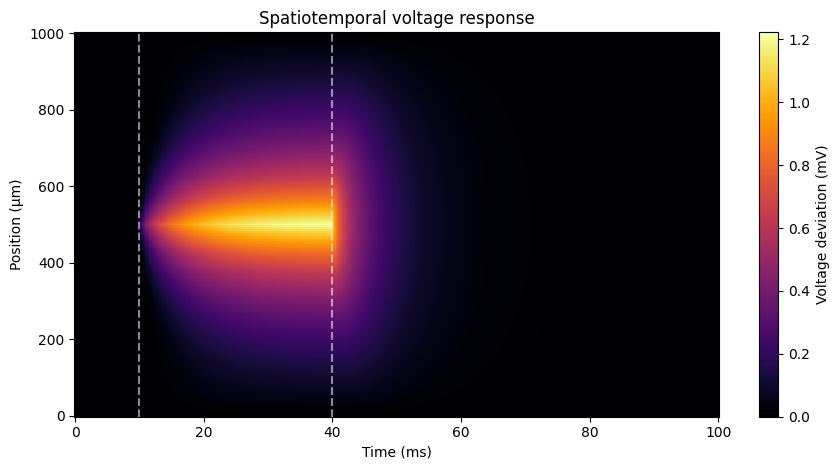

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.8))
p = ax.pcolormesh(sol.t_ms, sol.x_um, sol.voltage_mV, shading='auto', cmap='inferno')
fig.colorbar(p, ax=ax, label='Voltage deviation (mV)')
for t in (params.pulse_start_ms, params.pulse_end_ms):
    ax.axvline(t, color='white', linestyle='--', alpha=.55)
ax.set(xlabel='Time (ms)', ylabel='Position (µm)', title='Spatiotemporal voltage response')
fig.tight_layout()
plt.show()

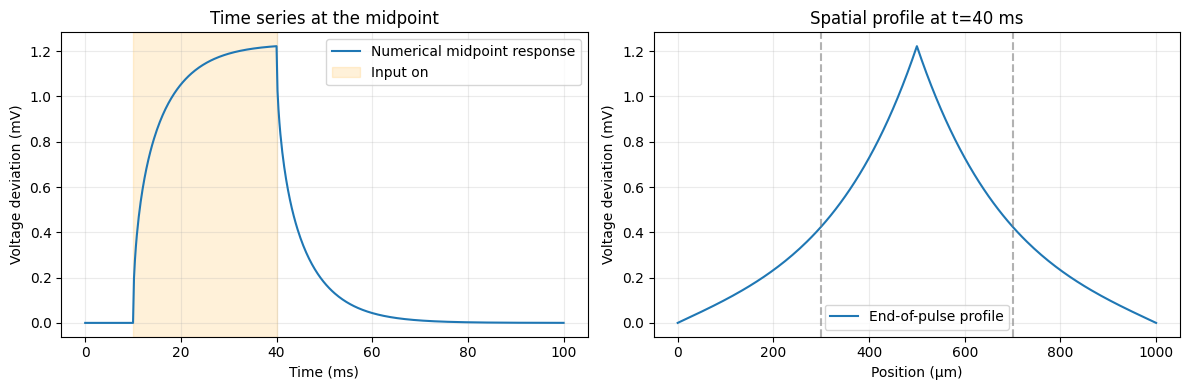

In [4]:
mid = params.n_points // 2
idx_end = int(np.argmin(np.abs(sol.t_ms - params.pulse_end_ms)))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(sol.t_ms, sol.voltage_mV[mid], label='Numerical midpoint response')
a1.axvspan(params.pulse_start_ms, params.pulse_end_ms, color='orange', alpha=.15, label='Input on')
a1.set(xlabel='Time (ms)', ylabel='Voltage deviation (mV)', title='Time series at the midpoint')
a1.legend(); a1.grid(alpha=.25)
a2.plot(sol.x_um, sol.voltage_mV[:, idx_end], label='End-of-pulse profile')
for pos in (params.length_um/2 - params.lambda_um, params.length_um/2 + params.lambda_um):
    a2.axvline(pos, color='gray', linestyle='--', alpha=.6)
a2.set(xlabel='Position (µm)', ylabel='Voltage deviation (mV)', title='Spatial profile at t=40 ms')
a2.legend(); a2.grid(alpha=.25)
fig.tight_layout()
plt.show()

## 5. An infinite-cable Green-function comparison

The **infinite-domain** fundamental solution of the diffusion–leak equation is

$$
G(x-y,u)=\frac{e^{-u/\tau}}{\sqrt{4\pi Du}}
\exp\!\left[-\frac{(x-y)^2}{4Du}\right],\qquad u>0.
$$

For zero initial voltage, convolution gives

$$
V(x,t)=\frac1\tau\int_0^t\!\int_{-\infty}^{\infty}
G(x-y,t-s)I(y,s)\,dy\,ds.
$$

To match the numerical centre-cell stimulus, the analytical forcing is treated as a **spatial box source one cell wide** (amplitude $I_0$), active from $t=10$ to 40 ms. The spatial Gaussian integral is evaluated using error functions and the remaining time integral using Gauss–Legendre quadrature.

Because the analytical reference is defined on the real line while the numerical cable is finite and has clamped endpoints, they are **not mathematically identical models**. We compare the central time course and the spatial profile near the midpoint, where boundary effects are comparatively small; we do not interpret boundary disagreement as integration failure.

Centre time-series RMSE: 0.007863 mV
Spatial RMSE inside ±lambda: 0.012805 mV


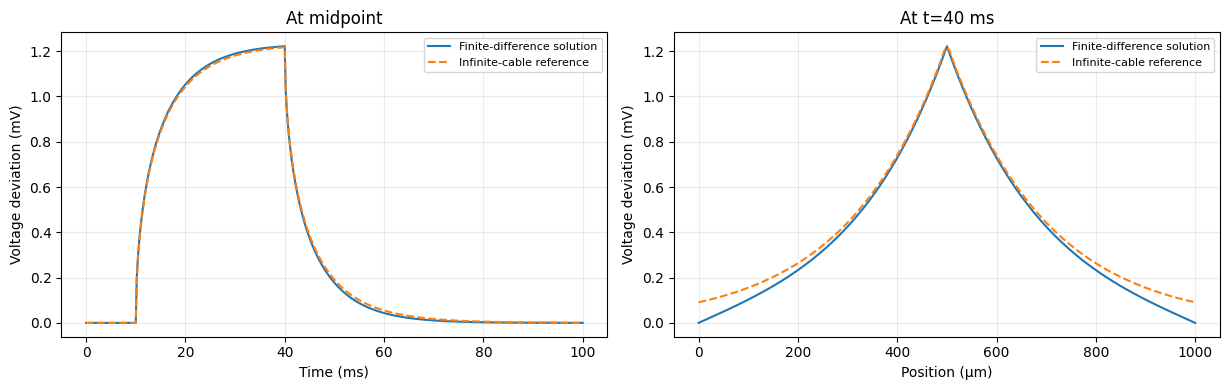

In [5]:
metrics, reference_center, reference_profile = calculate_validation(sol)
print(f"Centre time-series RMSE: {metrics['centre_temporal_rmse_mV']:.6f} mV")
print(f"Spatial RMSE inside ±lambda: {metrics['central_1lambda_profile_rmse_mV']:.6f} mV")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.4, 4))
a1.plot(sol.t_ms, sol.voltage_mV[mid], label='Finite-difference solution')
a1.plot(sol.t_ms, reference_center, '--', label='Infinite-cable reference')
a1.set(xlabel='Time (ms)', ylabel='Voltage deviation (mV)', title='At midpoint')
a1.legend(fontsize=8); a1.grid(alpha=.25)
a2.plot(sol.x_um, sol.voltage_mV[:, idx_end], label='Finite-difference solution')
a2.plot(sol.x_um, reference_profile, '--', label='Infinite-cable reference')
a2.set(xlabel='Position (µm)', ylabel='Voltage deviation (mV)', title='At t=40 ms')
a2.legend(fontsize=8); a2.grid(alpha=.25)
fig.tight_layout()
plt.show()

## 6. Interpretation, checks, and limitations

- With zero initial voltage, the computed voltage is zero before the pulse. The two endpoints remain exactly at resting voltage.
- Positive input produces a nonnegative voltage response.
- A small central mismatch with the infinite-cable Green function supports the consistency of the numerical implementation. It is **not** a rigorous global convergence result; refinement in $\Delta x$ and solver tolerances would be needed for that.
- The model is **passive, homogeneous and unbranched**. Ion-channel gating, active spikes, sealed-end boundaries, branching and physically calibrated electrode currents are outside its scope.

To save the standard figures and reproducible data files from the project folder, run `python main.py`. For optional parameter changes run `python main.py --help`. To run consistency tests execute `python -m unittest discover -s tests -v`.